# Phase 5d — Does Deterministic CLAP Change the Results?

Revision step 8b, part 2. Phase 2b re-extracted CLAP from three fixed 10-s windows per clip, replacing
one random, unseeded crop. This notebook re-runs the analyses that depend on the audio embedding with three
audio representations side by side:

| Name | What it is |
|---|---|
| `clap_rand` | Original Phase 2 CLAP (one random 10-s crop) |
| `clap_det` | Phase 2b CLAP (mean of three fixed 10-s windows) |
| `handcrafted` | Phase 2 librosa features (141-d), z-scored over the catalog, then cosine |

Analyses (same protocols as the earlier notebooks):
1. **Retrieval** on the shared split (Phase 5b/5c): audio-only, late fusion with SBERT (α re-tuned on shared
   validation for each audio variant) and early fusion. Metrics: quadrant P@K, nDCG@K (Gaussian AV relevance,
   σ = 0.10), AV distance. Paired bootstrap CIs and Wilcoxon (Pratt) with Holm.
2. **AV ridge probes** (Phase 4b protocol): shared 70/15/15 train → test; R², MAE, quadrant accuracy.
3. **Quadrant linear probe** (Phase 6b protocol): logistic regression, C tuned on validation macro-F1.
4. **Coherence** (Phase 4b protocol): 5-fold cross-fitted probes with bootstrap CIs, recomputed with `clap_det`.

AV values and quadrants are used for evaluation and probe targets only. `genres` is not read here.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon, spearmanr
from sklearn.linear_model import Ridge, RidgeCV, LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import r2_score, mean_absolute_error, f1_score

warnings.filterwarnings('ignore')

ROOT = os.environ.get('MUSIC_RESEARCH_ROOT', os.path.abspath('.'))
OUT_DIR = os.path.join(ROOT, 'outputs')
K_LIST  = [5, 10, 20]
ALPHAS  = [0.2, 0.4, 0.5, 0.6, 0.8]
SIGMA   = 0.10
N_BOOT  = 10_000
SEED    = 42
SCHEMES = {'tvt_70_15_15': '70/15/15', 'tvt_40_30_30': '40/30/30'}
rng = np.random.default_rng(SEED)

audio_df  = pd.read_parquet(os.path.join(OUT_DIR, 'audio_features.parquet'))
det_df    = pd.read_parquet(os.path.join(OUT_DIR, 'audio_features_clap_det.parquet'))
lyrics_df = pd.read_parquet(os.path.join(OUT_DIR, 'lyrics_features.parquet'))
merged    = pd.read_parquet(os.path.join(OUT_DIR, 'merged_dataset.parquet'))

def l2n(X):
    X = np.asarray(X, dtype=np.float64)
    return X / np.linalg.norm(X, axis=1, keepdims=True)

cat_sids = lyrics_df['song_id'].tolist()
cat_pos  = {s: i for i, s in enumerate(cat_sids)}
a_old = audio_df.set_index('song_id').loc[cat_sids]
a_det = det_df.set_index('song_id').loc[cat_sids]

hc = np.vstack(a_old['audio_handcrafted'].values).astype(np.float64)
AUDIO = {   # L2-normalized vectors for cosine retrieval / probes
    'clap_rand':   l2n(np.vstack(a_old['audio_clap'].values)),
    'clap_det':    l2n(np.vstack(a_det['audio_clap_det'].values)),
    'handcrafted': l2n(StandardScaler().fit_transform(hc)),     # unsupervised scaling over the catalog
}
AUDIO_RAW = {'clap_rand': np.vstack(a_old['audio_clap_raw'].values).astype(np.float64),
             'clap_det':  np.vstack(a_det['audio_clap_det_raw'].values).astype(np.float64)}
X_lyrics  = l2n(np.vstack(lyrics_df['lyrics_sbert'].values))
sbert_raw = np.vstack(lyrics_df['lyrics_sbert_raw'].values).astype(np.float64)

lab = merged.set_index('song_id').loc[cat_sids]
quad = lab['quadrant'].values
Y    = lab[['arousal', 'valence']].values.astype(np.float64)
D_AV = np.linalg.norm(Y[:, None] - Y[None], axis=-1)

mm = merged[merged['is_multimodal']]
lyr_stem_to_sid = {os.path.splitext(os.path.basename(p))[0]: s for s, p in zip(mm['song_id'], mm['lyrics_path'])}
def read_split(modality, scheme, subset):
    folder = 'MERGE_Audio_Balanced' if modality == 'audio' else 'MERGE_Lyrics_Balanced'
    ids = pd.read_csv(os.path.join(ROOT, folder, 'tvt_dataframes', scheme,
                                   f'{scheme}_{subset}_{modality}_balanced.csv'))['Song']
    return set(ids.map(lyr_stem_to_sid).dropna()) if modality == 'lyrics' else set(ids)
cat = set(cat_sids)
shared = {lbl: {sub: sorted(read_split('audio', sc, sub) & read_split('lyrics', sc, sub) & cat)
                for sub in ['train', 'validate', 'test']} for sc, lbl in SCHEMES.items()}
for lbl, d in shared.items():
    print(lbl, {k: len(v) for k, v in d.items()})
print('cos(clap_rand, clap_det) median:', np.median((AUDIO['clap_rand'] * AUDIO['clap_det']).sum(1)).round(3))

70/15/15 {'train': 1187, 'validate': 305, 'test': 302}
40/30/30 {'train': 475, 'validate': 616, 'test': 617}
cos(clap_rand, clap_det) median: 0.995


## 1. Retrieval on the shared split

In [2]:
S = {f'audio:{k}': v @ v.T for k, v in AUDIO.items()}
S['lyrics'] = X_lyrics @ X_lyrics.T
for k, raw in AUDIO_RAW.items():
    E = l2n(np.hstack([raw, sbert_raw])); S[f'early:{k}'] = E @ E.T

def scores(name, rows):
    if name.startswith('late:'):                 # late:<audio>:<alpha>
        _, a, al = name.split(':'); al = float(al)
        return al * S[f'audio:{a}'][rows] + (1 - al) * S['lyrics'][rows]
    return S[name][rows]

KMAX = max(K_LIST); DISC = 1 / np.log2(np.arange(2, KMAX + 2))
def evaluate(qs, names):
    rows = np.array([cat_pos[s] for s in qs])
    D = D_AV[rows].copy(); D[np.arange(len(rows)), rows] = np.inf
    idcg = np.cumsum(np.exp(-np.sort(D, 1)[:, :KMAX]**2 / (2 * SIGMA**2)) * DISC, 1)
    out = []
    for nm in names:
        sc = scores(nm, rows).copy(); sc[np.arange(len(rows)), rows] = -np.inf
        part = np.argpartition(-sc, KMAX, 1)[:, :KMAX]
        top = np.take_along_axis(part, np.take_along_axis(sc, part, 1).argsort(1)[:, ::-1], 1)
        d = np.take_along_axis(D_AV[rows], top, 1); hit = quad[top] == quad[rows][:, None]
        for k in K_LIST:
            out.append(pd.DataFrame({'strategy': nm, 'song_id': qs, 'k': k, 'quad_precision': hit[:, :k].mean(1),
                                     'ndcg': (np.exp(-d[:, :k]**2 / (2 * SIGMA**2)) * DISC[:k]).sum(1) / idcg[:, k - 1],
                                     'av_dist': d[:, :k].mean(1)}))
    return pd.concat(out, ignore_index=True)

best = {}
for lbl in SCHEMES.values():
    for a in ['clap_rand', 'clap_det', 'handcrafted']:
        rv = evaluate(shared[lbl]['validate'], [f'late:{a}:{al}' for al in ALPHAS])
        best[(lbl, a)] = rv[rv.k == 10].groupby('strategy').quad_precision.mean().idxmax()
    print(lbl, {a: best[(lbl, a)].split(':')[-1] for a in ['clap_rand', 'clap_det', 'handcrafted']})

per_query = []
for lbl in SCHEMES.values():
    names = ['audio:clap_rand', 'audio:clap_det', 'audio:handcrafted', 'lyrics',
             'early:clap_rand', 'early:clap_det'] + [best[(lbl, a)] for a in ['clap_rand', 'clap_det', 'handcrafted']]
    r = evaluate(shared[lbl]['test'], names); r['split'] = lbl; per_query.append(r)
per_query = pd.concat(per_query, ignore_index=True)
per_query['family'] = per_query.strategy.str.replace(r':\d\.\d$', '', regex=True)   # late:<audio> without α

def boot_ci(x):
    x = np.asarray(x, float); m = x[rng.integers(0, len(x), (N_BOOT, len(x)))].mean(1)
    return np.percentile(m, [2.5, 97.5])

summ = []
for (lbl, st, k), g in per_query.groupby(['split', 'strategy', 'k']):
    row = {'split': lbl, 'strategy': st, 'k': k, 'n': len(g)}
    for m in ['quad_precision', 'ndcg', 'av_dist']:
        lo, hi = boot_ci(g[m]); row.update({m: g[m].mean(), f'{m}_lo': lo, f'{m}_hi': hi})
    summ.append(row)
summary = pd.DataFrame(summ)
summary.to_csv(os.path.join(OUT_DIR, 'clap_det_retrieval_summary.csv'), index=False)
per_query.to_parquet(os.path.join(OUT_DIR, 'clap_det_retrieval_per_query.parquet'), index=False)

f = lambda r, m: f"{r[m]:.3f} [{r[m+'_lo']:.3f}, {r[m+'_hi']:.3f}]"
for lbl in SCHEMES.values():
    s = summary[(summary.split == lbl) & (summary.k == 10)]
    print(f'\n=== {lbl} shared test, K=10 (n={s.n.iloc[0]}) ===')
    print(pd.DataFrame({'Quad P@10': s.apply(lambda r: f(r, 'quad_precision'), axis=1).values,
                        'nDCG@10': s.apply(lambda r: f(r, 'ndcg'), axis=1).values,
                        'AV dist': s.apply(lambda r: f(r, 'av_dist'), axis=1).values}, index=s.strategy).to_string())

70/15/15 {'clap_rand': '0.4', 'clap_det': '0.5', 'handcrafted': '0.2'}


40/30/30 {'clap_rand': '0.6', 'clap_det': '0.6', 'handcrafted': '0.2'}



=== 70/15/15 shared test, K=10 (n=302) ===
                                 Quad P@10               nDCG@10               AV dist
strategy                                                                              
audio:clap_det        0.372 [0.345, 0.399]  0.267 [0.245, 0.290]  0.284 [0.273, 0.294]
audio:clap_rand       0.372 [0.345, 0.400]  0.258 [0.236, 0.280]  0.285 [0.274, 0.295]
audio:handcrafted     0.506 [0.472, 0.539]  0.350 [0.321, 0.381]  0.250 [0.237, 0.263]
early:clap_det        0.605 [0.571, 0.638]  0.428 [0.400, 0.456]  0.202 [0.190, 0.213]
early:clap_rand       0.604 [0.572, 0.638]  0.428 [0.401, 0.456]  0.202 [0.190, 0.214]
late:clap_det:0.5     0.620 [0.587, 0.653]  0.436 [0.408, 0.464]  0.200 [0.188, 0.212]
late:clap_rand:0.4    0.616 [0.583, 0.649]  0.431 [0.403, 0.459]  0.201 [0.189, 0.212]
late:handcrafted:0.2  0.665 [0.631, 0.698]  0.457 [0.428, 0.484]  0.193 [0.181, 0.205]
lyrics                0.601 [0.567, 0.635]  0.427 [0.399, 0.456]  0.202 [0.190, 0.214]

In [3]:
def holm(p):
    p = np.asarray(p); order = np.argsort(p); m = len(p); adj = np.empty(m); run = 0.0
    for rank, i in enumerate(order):
        run = max(run, (m - rank) * p[i]); adj[i] = min(1.0, run)
    return adj

tests = []
for lbl in SCHEMES.values():
    lr, ld, lh = best[(lbl, 'clap_rand')], best[(lbl, 'clap_det')], best[(lbl, 'handcrafted')]
    pairs = [('audio:clap_det', 'audio:clap_rand'), ('audio:clap_det', 'audio:handcrafted'),
             ('lyrics', 'audio:clap_det'), (ld, 'lyrics'), (ld, lr), (lh, 'lyrics'),
             ('early:clap_det', 'lyrics'), ('early:clap_det', 'early:clap_rand')]
    for k in K_LIST:
        sub = per_query[(per_query.split == lbl) & (per_query.k == k)]
        for metric in ['quad_precision', 'ndcg', 'av_dist']:
            wide = sub.pivot(index='song_id', columns='strategy', values=metric)
            fam = []
            for a, b in pairs:
                d = (wide[a] - wide[b]).values; lo, hi = boot_ci(d)
                p = wilcoxon(wide[a], wide[b], zero_method='pratt').pvalue if (d != 0).any() else 1.0
                fam.append({'split': lbl, 'k': k, 'metric': metric, 'A': a, 'B': b, 'mean_A': wide[a].mean(),
                            'mean_B': wide[b].mean(), 'diff': d.mean(), 'ci_lo': lo, 'ci_hi': hi, 'p_wilcoxon': p})
            for r, ph in zip(fam, holm([r['p_wilcoxon'] for r in fam])):
                r['p_holm'] = ph; r['significant_0.05'] = ph < 0.05
            tests += fam
tests = pd.DataFrame(tests)
tests.to_csv(os.path.join(OUT_DIR, 'clap_det_significance.csv'), index=False)
show = tests[(tests.k == 10) & (tests.metric != 'av_dist')].copy()
show['diff [95% CI]'] = show.apply(lambda r: f"{r['diff']:+.3f} [{r.ci_lo:+.3f}, {r.ci_hi:+.3f}]", axis=1)
for lbl in SCHEMES.values():
    print(f'\n=== {lbl}, K=10 (AV distance: see CSV) ===')
    print(show[show.split == lbl][['metric', 'A', 'B', 'diff [95% CI]', 'p_holm', 'significant_0.05']]
          .to_string(index=False, float_format=lambda x: f'{x:.2g}'))


=== 70/15/15, K=10 (AV distance: see CSV) ===
        metric                    A                  B           diff [95% CI]  p_holm  significant_0.05
quad_precision       audio:clap_det    audio:clap_rand -0.001 [-0.021, +0.020]       1             False
quad_precision       audio:clap_det  audio:handcrafted -0.134 [-0.170, -0.100] 9.8e-09              True
quad_precision               lyrics     audio:clap_det +0.230 [+0.188, +0.270] 2.4e-19              True
quad_precision    late:clap_det:0.5             lyrics +0.019 [+0.007, +0.030]  0.0012              True
quad_precision    late:clap_det:0.5 late:clap_rand:0.4 +0.004 [-0.003, +0.011]    0.58             False
quad_precision late:handcrafted:0.2             lyrics +0.064 [+0.039, +0.088] 2.6e-06              True
quad_precision       early:clap_det             lyrics +0.004 [+0.000, +0.007]     0.2             False
quad_precision       early:clap_det    early:clap_rand +0.001 [-0.001, +0.003]       1             False
        

## 2. AV ridge probes (Phase 4b protocol, shared 70/15/15 train → test)

In [4]:
RIDGE_ALPHAS = np.logspace(-2, 5, 15)
def to_quad(av):
    return np.where(av[:, 0] >= .5, np.where(av[:, 1] >= .5, 'Q1', 'Q2'), np.where(av[:, 1] >= .5, 'Q4', 'Q3'))
def make_probe(alpha=None):
    return make_pipeline(StandardScaler(), RidgeCV(alphas=RIDGE_ALPHAS) if alpha is None else Ridge(alpha=alpha))

msk = {sub: np.isin(cat_sids, shared['70/15/15'][sub]) for sub in ['train', 'validate', 'test']}
tr, va, te = msk['train'], msk['validate'], msk['test']
FEATS = {'audio: clap_rand': AUDIO['clap_rand'], 'audio: clap_det': AUDIO['clap_det'],
         'audio: handcrafted': hc, 'lyrics: SBERT': X_lyrics}
rows = []
for name, X in FEATS.items():
    p = make_probe().fit(X[tr], Y[tr]); P = p.predict(X[te])
    rows.append({'probe': name, 'ridge_alpha': p[-1].alpha_,
                 'R2_arousal': r2_score(Y[te, 0], P[:, 0]), 'R2_valence': r2_score(Y[te, 1], P[:, 1]),
                 'MAE_arousal': mean_absolute_error(Y[te, 0], P[:, 0]), 'MAE_valence': mean_absolute_error(Y[te, 1], P[:, 1]),
                 'quadrant_acc': np.mean(to_quad(P) == quad[te])})
av_probe = pd.DataFrame(rows)
print(av_probe.round(3).to_string(index=False))
av_probe.to_csv(os.path.join(OUT_DIR, 'clap_det_av_probe.csv'), index=False)

             probe  ridge_alpha  R2_arousal  R2_valence  MAE_arousal  MAE_valence  quadrant_acc
  audio: clap_rand     1000.000       0.199       0.080        0.088        0.191         0.394
   audio: clap_det      316.228       0.299       0.106        0.082        0.186         0.434
audio: handcrafted      316.228       0.434       0.158        0.071        0.177         0.586
     lyrics: SBERT     3162.278       0.373       0.519        0.074        0.121         0.679


## 3. Quadrant linear probe (Phase 6b protocol)

In [5]:
LP_FEATS = dict(FEATS)
LP_FEATS['early fusion: clap_rand+SBERT'] = l2n(np.hstack([AUDIO_RAW['clap_rand'], sbert_raw]))
LP_FEATS['early fusion: clap_det+SBERT']  = l2n(np.hstack([AUDIO_RAW['clap_det'], sbert_raw]))
C_GRID = np.logspace(-4, 2, 13)
lp_rows, preds = [], {}
for name, X in LP_FEATS.items():
    bestf = None
    for Cc in C_GRID:
        clf = make_pipeline(StandardScaler(), LogisticRegression(C=Cc, max_iter=5000)).fit(X[tr], quad[tr])
        f1 = f1_score(quad[va], clf.predict(X[va]), average='macro')
        if bestf is None or f1 > bestf[0]:
            bestf = (f1, Cc, clf)
    pred = bestf[2].predict(X[te]); preds[name] = pred
    corr = (pred == quad[te]).astype(float); lo, hi = boot_ci(corr)
    lp_rows.append({'features': name, 'C': bestf[1], 'test_acc': corr.mean(), 'acc_lo': lo, 'acc_hi': hi,
                    'test_macro_f1': f1_score(quad[te], pred, average='macro')})
lp = pd.DataFrame(lp_rows)
print(lp.round(3).to_string(index=False))
lp.to_csv(os.path.join(OUT_DIR, 'clap_det_linear_probe.csv'), index=False)

print('\nPaired accuracy differences (bootstrap 95% CI):')
for a, b in [('audio: clap_det', 'audio: clap_rand'), ('audio: clap_det', 'audio: handcrafted'),
             ('lyrics: SBERT', 'audio: clap_det'), ('early fusion: clap_det+SBERT', 'lyrics: SBERT'),
             ('early fusion: clap_det+SBERT', 'early fusion: clap_rand+SBERT')]:
    d = (preds[a] == quad[te]).astype(float) - (preds[b] == quad[te]).astype(float)
    lo, hi = boot_ci(d)
    print(f'  {a} − {b}: {d.mean():+.3f} [{lo:+.3f}, {hi:+.3f}]')

                     features     C  test_acc  acc_lo  acc_hi  test_macro_f1
             audio: clap_rand 0.032     0.434   0.377   0.490          0.441
              audio: clap_det 0.032     0.497   0.440   0.553          0.503
           audio: handcrafted 0.100     0.603   0.546   0.656          0.603
                lyrics: SBERT 0.001     0.722   0.669   0.772          0.718
early fusion: clap_rand+SBERT 0.003     0.758   0.709   0.805          0.759
 early fusion: clap_det+SBERT 0.003     0.758   0.709   0.805          0.760

Paired accuracy differences (bootstrap 95% CI):
  audio: clap_det − audio: clap_rand: +0.063 [+0.003, +0.123]
  audio: clap_det − audio: handcrafted: -0.106 [-0.172, -0.040]
  lyrics: SBERT − audio: clap_det: +0.225 [+0.149, +0.301]
  early fusion: clap_det+SBERT − lyrics: SBERT: +0.036 [+0.000, +0.073]
  early fusion: clap_det+SBERT − early fusion: clap_rand+SBERT: +0.000 [-0.026, +0.026]


## 4. Coherence with deterministic CLAP (Phase 4b protocol)

Cross-fitted ridge probes (5 folds) with 200 bootstrap refits per fold, cosine coherence around (0.5, 0.5).
A track is a **robust paradox** if the whole 95% CI is below 0. Results are compared with `coherence_v2.parquet`
(the same analysis on `clap_rand`).

In [6]:
N_BOOT_COH, CENTER = 200, np.array([0.5, 0.5])
def cos_coh(A, L):
    A, L = A - CENTER, L - CENTER
    return (A * L).sum(-1) / (np.linalg.norm(A, axis=-1) * np.linalg.norm(L, axis=-1) + 1e-12)

X_a = AUDIO['clap_det']; X_l = X_lyrics.copy()
n = len(cat_sids); crng = np.random.default_rng(SEED)
pred_a, pred_l = np.zeros((n, 2)), np.zeros((n, 2))
boot_a, boot_l = np.zeros((N_BOOT_COH, n, 2)), np.zeros((N_BOOT_COH, n, 2))
for fo, (itr, ite) in enumerate(StratifiedKFold(5, shuffle=True, random_state=SEED).split(X_a, quad)):
    pa = make_probe().fit(X_a[itr], Y[itr]); pl = make_probe().fit(X_l[itr], Y[itr])
    pred_a[ite], pred_l[ite] = pa.predict(X_a[ite]), pl.predict(X_l[ite])
    for b in range(N_BOOT_COH):
        ib = crng.choice(itr, size=len(itr), replace=True)
        boot_a[b, ite] = make_probe(pa[-1].alpha_).fit(X_a[ib], Y[ib]).predict(X_a[ite])
        boot_l[b, ite] = make_probe(pl[-1].alpha_).fit(X_l[ib], Y[ib]).predict(X_l[ite])
    print(f'fold {fo}: ridge α audio={pa[-1].alpha_:.0f} lyrics={pl[-1].alpha_:.0f}')

print(f'Out-of-fold R² audio (clap_det): arousal {r2_score(Y[:,0], pred_a[:,0]):.3f}  valence {r2_score(Y[:,1], pred_a[:,1]):.3f}')
coh = pd.DataFrame({'song_id': cat_sids, 'quadrant': quad, 'coh_cos': cos_coh(pred_a, pred_l),
                    'pred_audio_arousal': pred_a[:, 0], 'pred_audio_valence': pred_a[:, 1],
                    'pred_lyrics_arousal': pred_l[:, 0], 'pred_lyrics_valence': pred_l[:, 1]})
bs = cos_coh(boot_a, boot_l)
coh['coh_cos_lo'], coh['coh_cos_hi'] = np.percentile(bs, [2.5, 97.5], axis=0)
coh['status_cos'] = np.select([coh.coh_cos_hi < 0, coh.coh_cos_lo > 0], ['robust paradox', 'robust coherent'], 'uncertain')
coh['err_audio']  = np.linalg.norm(pred_a - Y, axis=1); coh['err_lyrics'] = np.linalg.norm(pred_l - Y, axis=1)

old = pd.read_parquet(os.path.join(OUT_DIR, 'coherence_v2.parquet')).set_index('song_id').loc[cat_sids]
print(f"\nSpearman(coherence clap_rand, clap_det) = {spearmanr(old.coh_cos, coh.coh_cos)[0]:.3f}")
cmp = pd.DataFrame({'clap_rand': old.status_cos.value_counts(), 'clap_det': coh.status_cos.value_counts()})
cmp.loc['point estimate < 0'] = [(old.coh_cos < 0).sum(), (coh.coh_cos < 0).sum()]
print(cmp.to_string())
both = (old.status_cos.values == 'robust paradox') & (coh.status_cos.values == 'robust paradox')
print(f'robust paradoxes in both: {both.sum()}')
rp = coh[coh.status_cos == 'robust paradox']
print(f'In robust paradoxes, the audio probe is the worse one: {np.mean(rp.err_audio > rp.err_lyrics):.0%}')

def wilson(k, nn, z=1.96):
    p = k / nn; d = 1 + z**2 / nn; c = (p + z**2 / (2 * nn)) / d
    h = z * np.sqrt(p * (1 - p) / nn + z**2 / (4 * nn**2)) / d
    return c - h, c + h
qrows = []
for q in ['Q1', 'Q2', 'Q3', 'Q4']:
    g, go = coh[coh.quadrant == q], old[old.quadrant == q]
    k = (g.status_cos == 'robust paradox').sum(); lo, hi = wilson(k, len(g))
    qrows.append({'quadrant': q, 'n': len(g), 'mean_cos_det': g.coh_cos.mean(), 'mean_cos_rand': go.coh_cos.mean(),
                  'robust_paradox_det': k / len(g), 'ci_lo': lo, 'ci_hi': hi,
                  'robust_paradox_rand': (go.status_cos == 'robust paradox').mean()})
print(pd.DataFrame(qrows).round(3).to_string(index=False))
coh.to_parquet(os.path.join(OUT_DIR, 'coherence_clap_det.parquet'), index=False)
print('Saved: coherence_clap_det.parquet')

fold 0: ridge α audio=316 lyrics=3162


fold 1: ridge α audio=316 lyrics=3162


fold 2: ridge α audio=316 lyrics=3162


fold 3: ridge α audio=1000 lyrics=3162


fold 4: ridge α audio=316 lyrics=3162
Out-of-fold R² audio (clap_det): arousal 0.280  valence 0.158

Spearman(coherence clap_rand, clap_det) = 0.758
                    clap_rand  clap_det
status_cos                             
robust coherent           976      1020
uncertain                 964       928
robust paradox            135       127
point estimate < 0        507       478
robust paradoxes in both: 81
In robust paradoxes, the audio probe is the worse one: 78%
quadrant   n  mean_cos_det  mean_cos_rand  robust_paradox_det  ci_lo  ci_hi  robust_paradox_rand
      Q1 509         0.449          0.433               0.035  0.022  0.055                0.039
      Q2 583         0.388          0.321               0.099  0.078  0.126                0.118
      Q3 480         0.314          0.271               0.081  0.060  0.109                0.077
      Q4 503         0.650          0.652               0.024  0.014  0.041                0.018
Saved: coherence_clap_det.parquet


## 5. Figure: audio representation comparison

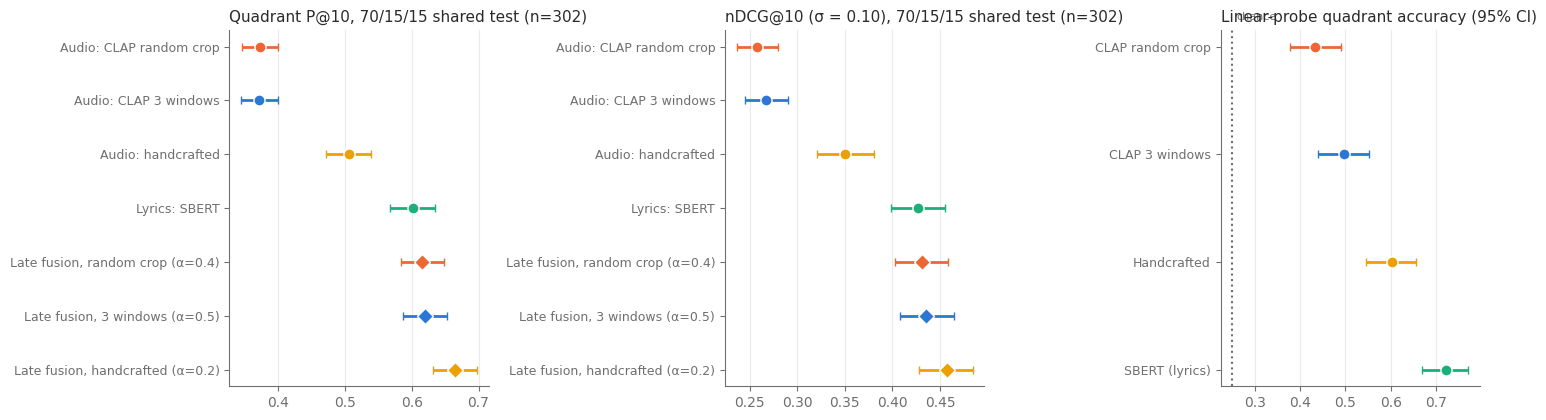

Saved: clap_det_comparison.png


In [7]:
COL = {'clap_rand': '#eb6834', 'clap_det': '#2a78d6', 'handcrafted': '#eda100', 'lyrics': '#1baf7a'}
INK, MUTED = '#2b2b2b', '#6f6f6f'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': MUTED,
                     'xtick.color': MUTED, 'ytick.color': MUTED, 'axes.labelcolor': INK, 'font.size': 10})
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
s = summary[(summary.split == '70/15/15') & (summary.k == 10)].set_index('strategy')
items = [('audio:clap_rand', 'Audio: CLAP random crop', 'clap_rand'), ('audio:clap_det', 'Audio: CLAP 3 windows', 'clap_det'),
         ('audio:handcrafted', 'Audio: handcrafted', 'handcrafted'), ('lyrics', 'Lyrics: SBERT', 'lyrics'),
         (best[('70/15/15', 'clap_rand')], f"Late fusion, random crop (α={best[('70/15/15','clap_rand')][-3:]})", 'clap_rand'),
         (best[('70/15/15', 'clap_det')], f"Late fusion, 3 windows (α={best[('70/15/15','clap_det')][-3:]})", 'clap_det'),
         (best[('70/15/15', 'handcrafted')], f"Late fusion, handcrafted (α={best[('70/15/15','handcrafted')][-3:]})", 'handcrafted')]
for ax, m, title in [(axes[0], 'quad_precision', 'Quadrant P@10'), (axes[1], 'ndcg', 'nDCG@10 (σ = 0.10)')]:
    y = np.arange(len(items))[::-1]
    for yi, (st, name, c) in zip(y, items):
        r = s.loc[st]
        ax.errorbar(r[m], yi, xerr=[[r[m] - r[f'{m}_lo']], [r[f'{m}_hi'] - r[m]]], fmt='o' if 'late' not in st else 'D',
                    color=COL[c], ms=8, capsize=3, mec='white', mew=1, lw=2)
    ax.set_yticks(y); ax.set_yticklabels([i[1] for i in items], fontsize=9)
    ax.set_title(f'{title}, 70/15/15 shared test (n={int(s.n.iloc[0])})', fontsize=11, loc='left', color=INK)
    ax.grid(axis='x', alpha=0.25)
ax = axes[2]
names = ['audio: clap_rand', 'audio: clap_det', 'audio: handcrafted', 'lyrics: SBERT']
cols = [COL['clap_rand'], COL['clap_det'], COL['handcrafted'], COL['lyrics']]
lpp = lp.set_index('features').loc[names]
y = np.arange(len(names))[::-1]
for yi, nm, c in zip(y, names, cols):
    r = lpp.loc[nm]
    ax.errorbar(r.test_acc, yi, xerr=[[r.test_acc - r.acc_lo], [r.acc_hi - r.test_acc]], fmt='o', color=c, ms=8, capsize=3,
                mec='white', mew=1, lw=2)
ax.axvline(0.25, color=MUTED, ls=':', lw=1.5); ax.text(0.26, y[0] + 0.25, 'chance', color=MUTED, fontsize=8)
ax.set_yticks(y); ax.set_yticklabels(['CLAP random crop', 'CLAP 3 windows', 'Handcrafted', 'SBERT (lyrics)'], fontsize=9)
ax.set_title('Linear-probe quadrant accuracy (95% CI)', fontsize=11, loc='left', color=INK); ax.grid(axis='x', alpha=0.25)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'clap_det_comparison.png'), dpi=200, bbox_inches='tight')
plt.show()
print('Saved: clap_det_comparison.png')